# Step 1 — Train yolo26s, verify it's stock, then localize the weakness to a component

This is the diagnostic step that decides your whole paper. It does **not** try to ablate every
YOLO26 internal (most aren't toggleable). Instead it produces the one clean, controlled result you
*can* get — **one-to-one (NMS-free) vs one-to-many head branch** — plus behavioral probes that
point at the responsible component. The output tells you which lever to build your method on.

Flow:
1. **Part 0** — setup + dataset import.
2. **Part V** — verify the trained model is the *stock* YOLO26 architecture (param count, head type,
   config file) before spending GPU-hours, so the paper's "base model" claim is defensible.
3. **Part T** — train one fresh `yolo26s`, 100 epochs. Skips if already trained.
4. **Part A–D** — split audit, stratified evaluation, TIDE error decomposition, anchor coverage,
   verdict (where the base model fails).
5. **Part E** — head-branch ablation: decode o2o vs o2m from the same weights, compare per
   aspect-ratio bucket. **Self-validating**: the decoder must reproduce `model.predict()` before any
   number is trusted.

The Part-D verdict + Part-E head deltas together pick your Phase-2 lever (see the plan doc).

Classes: `0 D00 longitudinal, 1 D10 transverse, 2 D20 alligator, 3 D40 pothole, 4 repair`.

## Part 0 — Setup & dataset import

In [ ]:
!pip -q install ultralytics pyyaml pandas matplotlib pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.1 MB/s eta 0:00:00


In [ ]:
import ultralytics, torch
import numpy as np, pandas as pd, json
import matplotlib.pyplot as plt
from PIL import Image
print('ultralytics:', ultralytics.__version__, '| torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics: 8.4.104 | torch: 2.11.0+cu128 | CUDA: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil, zipfile
from pathlib import Path
import yaml

# ---------------- CONFIG ----------------
DRIVE_ZIP  = Path('/content/drive/MyDrive/Research/Dataset/China_Subset.zip')
LOCAL_ZIP  = Path('/content/China_Subset.zip')
LOCAL_ROOT = Path('/content/China_Subset')

RUNS_ROOT  = Path('/content/drive/MyDrive/Research/runs_rdd2022')
RUN_NAME   = 'yolo26s_base_fresh'
TRAIN_DIR  = RUNS_ROOT / 'yolo26s_base'
OUT_DIR    = RUNS_ROOT / 'yolo26s_base' / 'diagnostics'
CACHE_DIR  = OUT_DIR / 'pred_cache'
HEAD_CACHE = OUT_DIR / 'head_cache'

BASE_MODEL = 'yolo26s'      # if invalid in your ultralytics version, Part T errors -> tell me the right string
EPOCHS     = 100
# expected stock yolo26s sanity bounds (param count ~9.5M); adjust if your build differs
EXPECT_PARAMS_RANGE = (8.0e6, 11.5e6)

CLASS_NAMES = ['longitudinal crack', 'transverse crack', 'alligator crack', 'pothole', 'repair']
SPLITS      = ['train_set', 'valid_set', 'test_set']
EVAL_SPLITS = ['valid_set', 'test_set']
IMGSZ, CONF_EVAL, CONF_OP, MAX_DET, NMS_IOU = 640, 0.001, 0.25, 300, 0.7
BOOTSTRAP_ITERS = 300
FORCE_REINFER   = False

if not LOCAL_ROOT.exists():
    assert DRIVE_ZIP.exists(), f'Zip not found: {DRIVE_ZIP}'
    shutil.copy2(DRIVE_ZIP, LOCAL_ZIP)
    with zipfile.ZipFile(LOCAL_ZIP, 'r') as zf:
        zf.extractall('/content')
    print('extracted to', LOCAL_ROOT)
else:
    print('dataset already present at', LOCAL_ROOT)

test_rel = 'test_set/images' if (LOCAL_ROOT / 'test_set' / 'images').exists() else None
data_config = dict(path=str(LOCAL_ROOT), train='train_set/images', val='valid_set/images', nc=5, names=CLASS_NAMES)
if test_rel:
    data_config['test'] = test_rel
yaml_path = LOCAL_ROOT / 'dataset.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(data_config, f, sort_keys=False)

for d in (TRAIN_DIR, OUT_DIR, CACHE_DIR, HEAD_CACHE):
    d.mkdir(parents=True, exist_ok=True)

print('yaml:', yaml_path, '| test split:', data_config.get('test', 'None'))
for split in SPLITS:
    idir = LOCAL_ROOT / split / 'images'; ldir = LOCAL_ROOT / split / 'labels'
    print(f'[{split}] images={len(list(idir.glob("*"))) if idir.exists() else "MISSING"} '
          f'labels={len(list(ldir.glob("*.txt"))) if ldir.exists() else "MISSING"}')

extracted to /content/China_Subset
yaml: /content/China_Subset/dataset.yaml | test split: test_set/images
[train_set] images=3502 labels=3502
[valid_set] images=438 labels=438
[test_set] images=438 labels=438


## Part V — Verify the model is the stock YOLO26 architecture

Runs **before** training so you don't spend GPU-hours on a model that isn't what the paper claims.
Prints the config file, module/param counts, and the detection-head type, and asserts the param
count is in the expected range. If the head isn't the end-to-end (NMS-free) YOLO26 head, or the
param count is off, stop and fix the model string before proceeding.

In [ ]:
from ultralytics import YOLO
device = 0 if torch.cuda.is_available() else 'cpu'

_m = YOLO(BASE_MODEL)
n_params = sum(p.numel() for p in _m.model.parameters())
n_modules = len(list(_m.model.modules()))
head = _m.model.model[-1]
print('model class :', type(_m.model).__name__)
print('config yaml :', getattr(_m.model, 'yaml_file', 'n/a'))
print('modules     :', n_modules)
print('parameters  :', f'{n_params:,} ({n_params/1e6:.2f}M)')
print('head type   :', type(head).__name__)
print('  end2end   :', getattr(head, 'end2end', None))
print('  nc        :', getattr(head, 'nc', None))
print('  reg_max   :', getattr(head, 'reg_max', None))
print('  strides   :', [float(s) for s in getattr(head, 'stride', [])] if hasattr(head, 'stride') else 'n/a')

assert EXPECT_PARAMS_RANGE[0] <= n_params <= EXPECT_PARAMS_RANGE[1],     f'param count {n_params/1e6:.2f}M outside expected {EXPECT_PARAMS_RANGE[0]/1e6:.1f}-{EXPECT_PARAMS_RANGE[1]/1e6:.1f}M for stock yolo26s -- architecture may be modified'
if not getattr(head, 'end2end', False):
    print('\n*** WARNING: head is not end-to-end. The one-to-one/one-to-many branch ablation (Part E)')
    print('    needs the NMS-free e2e head. Verify BASE_MODEL is the real YOLO26 before relying on Part E.')
else:
    print('\nOK: stock end-to-end YOLO26 head detected -- head-branch ablation applicable.')
del _m

model class : DetectionModel
config yaml : n/a
modules     : 454
parameters  : 10,009,784 (10.01M)
head type   : Detect
  end2end   : True
  nc        : 80
  reg_max   : 1
  strides   : [8.0, 16.0, 32.0]

OK: stock end-to-end YOLO26 head detected -- head-branch ablation applicable.


## Part T — Train the fresh yolo26s base model (100 epochs)

SGD recipe matching your prior runs, 100 epochs. Skips automatically if `best.pt` exists.

In [ ]:
CKPT = TRAIN_DIR / RUN_NAME / 'weights' / 'best.pt'
if CKPT.exists():
    print('already trained, skipping:', CKPT)
else:
    print(f'training {BASE_MODEL} for {EPOCHS} epochs ->', TRAIN_DIR / RUN_NAME)
    YOLO(BASE_MODEL).train(
        data=str(yaml_path), project=str(TRAIN_DIR), name=RUN_NAME, exist_ok=True,
        epochs=EPOCHS, imgsz=IMGSZ, batch=16, device=device, workers=8, pretrained=True,
        optimizer='SGD', lr0=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3,
        hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, translate=0.1, scale=0.5, fliplr=0.5, mosaic=1.0,
        degrees=0.0, shear=0.0, perspective=0.0, flipud=0.0, mixup=0.0, copy_paste=0.0,
        patience=0, save=True, amp=True, cache='disk', val=True, plots=True, seed=0)
assert CKPT.exists(), f'training did not produce {CKPT}'
print('checkpoint ready:', CKPT)

already trained, skipping: /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_base/yolo26s_base_fresh/weights/best.pt
checkpoint ready: /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_base/yolo26s_base_fresh/weights/best.pt


In [ ]:
# official ultralytics metric read, as a baseline number
best = YOLO(str(CKPT))
m = best.val(data=str(yaml_path), split='test', imgsz=IMGSZ, batch=8, device=device, verbose=False)
print(f"test  mAP50: {m.box.map50:.3f} | mAP50-95: {m.box.map:.3f} | P: {m.box.mp:.3f} | R: {m.box.mr:.3f}")
for i, name in m.names.items():
    print(f'  {name:<22} mAP50-95: {m.box.maps[i]:.3f}')

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,467,115 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1699.7±515.3 MB/s, size: 65.2 KB)
val: Scanning /content/China_Subset/test_set/labels... 438 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 438/438 1.7Kit/s 0.3s
val: New cache created: /content/China_Subset/test_set/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 6.6it/s 8.4s
                   all        438        893      0.829      0.838      0.854      0.578
Speed: 1.4ms preprocess, 9.2ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /content/runs/detect/val
test  mAP50: 0.854 | mAP50-95: 0.578 | P: 0.829 | R: 0.838
  longitudinal crack     mAP50-95: 0.532
  transverse crack       mAP50-95: 0.536
  alligator crack        mAP50-95: 0.555
  pothole                

_Shared analysis functions. Run once._

In [ ]:
# ---------------------------------------------------------------
# Dataset inventory: parse filenames, labels, image sizes.
# ---------------------------------------------------------------
import json
import math
import re
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
NAME_RE = re.compile(r'^(?P<source>[A-Za-z]+_[A-Za-z]+)_(?P<frame>\d+)$')


def parse_source_frame(stem: str):
    """'China_Drone_000123' -> ('China_Drone', 123). Unknown patterns -> (stem, None)."""
    m = NAME_RE.match(stem)
    if m:
        return m.group('source'), int(m.group('frame'))
    return stem, None


def yolo_line_to_xyxy(parts, W, H):
    cls, xc, yc, w, h = float(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
    bw, bh = w * W, h * H
    x1, y1 = xc * W - bw / 2.0, yc * H - bh / 2.0
    return int(cls), np.array([x1, y1, x1 + bw, y1 + bh], dtype=np.float32)


def box_geometry(boxes: np.ndarray):
    """boxes (N,4) xyxy -> (ar, sqrt_area) each (N,)."""
    if len(boxes) == 0:
        return np.zeros(0), np.zeros(0)
    w = np.maximum(boxes[:, 2] - boxes[:, 0], 1e-9)
    h = np.maximum(boxes[:, 3] - boxes[:, 1], 1e-9)
    ar = np.maximum(w, h) / np.minimum(w, h)
    sa = np.sqrt(w * h)
    return ar, sa


def build_inventory(dataset_root: Path, splits, class_names):
    """Returns (images_df, boxes_df, gts) where gts[split][stem] = dict(boxes, cls, W, H, path)."""
    img_rows, box_rows = [], []
    gts = {s: {} for s in splits}
    for split in splits:
        img_dir = dataset_root / split / 'images'
        lbl_dir = dataset_root / split / 'labels'
        if not img_dir.exists():
            continue
        for img_path in sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS):
            stem = img_path.stem
            source, frame = parse_source_frame(stem)
            with Image.open(img_path) as im:
                W, H = im.size
            boxes, clss = [], []
            lbl = lbl_dir / f'{stem}.txt'
            if lbl.exists():
                for line in lbl.read_text().strip().splitlines():
                    parts = line.split()
                    if len(parts) >= 5:
                        c, b = yolo_line_to_xyxy(parts, W, H)
                        boxes.append(b)
                        clss.append(c)
            boxes = np.stack(boxes) if boxes else np.zeros((0, 4), np.float32)
            clss = np.array(clss, dtype=int)
            ar, sa = box_geometry(boxes)
            img_rows.append(dict(split=split, stem=stem, source=source, frame=frame,
                                 W=W, H=H, n_boxes=len(boxes), path=str(img_path)))
            for i in range(len(boxes)):
                box_rows.append(dict(split=split, stem=stem, source=source,
                                     cls=int(clss[i]),
                                     cls_name=class_names[clss[i]] if clss[i] < len(class_names) else str(clss[i]),
                                     x1=float(boxes[i, 0]), y1=float(boxes[i, 1]),
                                     x2=float(boxes[i, 2]), y2=float(boxes[i, 3]),
                                     W=W, H=H, ar=float(ar[i]), sqrt_area=float(sa[i])))
            gts[split][stem] = dict(boxes=boxes, cls=clss, W=W, H=H, path=str(img_path), source=source)
    return pd.DataFrame(img_rows), pd.DataFrame(box_rows), gts

In [ ]:
# ---------------------------------------------------------------
# Stratification buckets for aspect ratio and size.
# ---------------------------------------------------------------
AR_EDGES = [2.0, 4.0, 8.0]
AR_LABELS = ['AR<2', 'AR2-4', 'AR4-8', 'AR>=8']
SIZE_EDGES = [32.0, 96.0]           # sqrt(area) in original pixels, COCO-style
SIZE_LABELS = ['small(<32)', 'medium(32-96)', 'large(>=96)']


def bucket_of(values, edges, labels):
    values = np.asarray(values, dtype=float)
    idx = np.searchsorted(edges, values, side='right')
    return np.array(labels, dtype=object)[idx]


def ar_bucket(values):
    return bucket_of(values, AR_EDGES, AR_LABELS)


def size_bucket(values):
    return bucket_of(values, SIZE_EDGES, SIZE_LABELS)

In [ ]:
# ---------------------------------------------------------------
# IoU, COCO-style matching with "ignore" strata, 101-pt AP.
# ---------------------------------------------------------------

def iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """a (N,4), b (M,4) xyxy -> IoU (N,M)."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ax1, ay1, ax2, ay2 = a[:, 0, None], a[:, 1, None], a[:, 2, None], a[:, 3, None]
    bx1, by1, bx2, by2 = b[None, :, 0], b[None, :, 1], b[None, :, 2], b[None, :, 3]
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(ax1, bx1), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(ay1, by1), 0, None)
    inter = iw * ih
    area_a = np.clip(ax2 - ax1, 0, None) * np.clip(ay2 - ay1, 0, None)
    area_b = np.clip(bx2 - bx1, 0, None) * np.clip(by2 - by1, 0, None)
    return inter / np.clip(area_a + area_b - inter, 1e-9, None)


def match_image(dt_conf, gt_ignore, iou, thr):
    """COCO-style greedy match for one image, one class, one IoU threshold.

    dt_conf (Nd,), gt_ignore (Ng,) bool, iou (Nd,Ng).
    Returns dt_tp (Nd,) bool, dt_matched_ignored (Nd,) bool, gt_matched (Ng,) bool.
    Detections are processed in descending confidence. A detection first tries the
    best non-ignored unmatched GT with IoU>=thr; failing that, it may match an
    ignored GT (and is then excluded from TP/FP counting).
    """
    nd, ng = len(dt_conf), len(gt_ignore)
    dt_tp = np.zeros(nd, bool)
    dt_ig = np.zeros(nd, bool)
    gt_m = np.zeros(ng, bool)
    if nd == 0 or ng == 0:
        return dt_tp, dt_ig, gt_m
    for d in np.argsort(-dt_conf):
        best_g, best_i = -1, thr
        best_ig_g, best_ig_i = -1, thr
        for g in range(ng):
            v = iou[d, g]
            if v < thr:
                continue
            if gt_ignore[g]:
                if v >= best_ig_i:
                    best_ig_g, best_ig_i = g, v
            elif not gt_m[g]:
                if v >= best_i:
                    best_g, best_i = g, v
        if best_g >= 0:
            gt_m[best_g] = True
            dt_tp[d] = True
        elif best_ig_g >= 0:
            dt_ig[d] = True
    return dt_tp, dt_ig, gt_m


def ap_101(conf, tp, npos):
    """101-point interpolated AP from (conf, tp) of non-ignored detections."""
    if npos == 0:
        return float('nan')
    if len(conf) == 0:
        return 0.0
    order = np.argsort(-conf)
    tp = np.asarray(tp, float)[order]
    ctp = np.cumsum(tp)
    cfp = np.cumsum(1.0 - tp)
    recall = ctp / npos
    prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.concatenate([[0.0], recall])
    mpre = np.concatenate([[1.0], prec])
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    # COCO-style: p(x) = max precision at recall >= x  (envelope is non-increasing,
    # so the first index with mrec >= x gives that max; beyond max recall -> 0)
    x = np.linspace(0, 1, 101)
    idx = np.searchsorted(mrec, x, side='left')
    y = np.where(idx < len(mpre), mpre[np.clip(idx, 0, len(mpre) - 1)], 0.0)
    return float(np.mean(y))


IOU_THRS = np.round(np.arange(0.5, 1.0, 0.05), 2)  # 0.5 ... 0.95


def evaluate(preds, gts, classes, iou_thrs=IOU_THRS,
             gt_keep_fn=None, det_keep_fn=None, collect_per_image=False):
    """Stratified COCO-style evaluation.

    preds[stem] = dict(boxes (N,4), conf (N,), cls (N,))
    gts[stem]   = dict(boxes (M,4), cls (M,))
    gt_keep_fn(boxes)->bool arr : GTs outside the stratum are *ignored* (COCO-style).
    det_keep_fn(boxes)->bool arr: unmatched detections outside the stratum are ignored.

    Returns dict with per-class AP per threshold, pooled AP per threshold,
    npos per class, and (optionally) per-image records for bootstrapping.
    """
    nt = len(iou_thrs)
    per_cls = {c: dict(conf=[], tp=[], ig=[]) for c in classes}
    npos = {c: 0 for c in classes}
    per_image = {}

    for stem, gt in gts.items():
        pr = preds.get(stem, dict(boxes=np.zeros((0, 4)), conf=np.zeros(0), cls=np.zeros(0, int)))
        img_conf, img_tp = [], []
        img_npos = 0
        for c in classes:
            g_sel = gt['cls'] == c
            d_sel = pr['cls'] == c
            g_boxes = gt['boxes'][g_sel]
            d_boxes = pr['boxes'][d_sel]
            d_conf = pr['conf'][d_sel]
            g_ig = np.zeros(len(g_boxes), bool)
            if gt_keep_fn is not None and len(g_boxes):
                g_ig = ~gt_keep_fn(g_boxes)
            npos[c] += int((~g_ig).sum())
            img_npos += int((~g_ig).sum())
            if len(d_boxes) == 0:
                continue
            iou = iou_matrix(d_boxes, g_boxes)
            tp_mat = np.zeros((len(d_boxes), nt), bool)
            ig_mat = np.zeros((len(d_boxes), nt), bool)
            for ti, thr in enumerate(iou_thrs):
                dt_tp, dt_ig, _ = match_image(d_conf, g_ig, iou, thr)
                tp_mat[:, ti] = dt_tp
                ig_mat[:, ti] = dt_ig
            if det_keep_fn is not None:
                d_out = ~det_keep_fn(d_boxes)
                unmatched = ~tp_mat
                ig_mat = ig_mat | (unmatched & d_out[:, None])
            per_cls[c]['conf'].append(d_conf)
            per_cls[c]['tp'].append(tp_mat)
            per_cls[c]['ig'].append(ig_mat)
            img_conf.append(d_conf)
            img_tp.append(tp_mat)
        if collect_per_image:
            per_image[stem] = dict(
                conf=np.concatenate(img_conf) if img_conf else np.zeros(0),
                tp=np.concatenate(img_tp) if img_tp else np.zeros((0, nt), bool),
                npos=img_npos,
            )

    ap_cls = {}
    pooled_conf, pooled_tp, pooled_ig = [], [], []
    for c in classes:
        if per_cls[c]['conf']:
            conf = np.concatenate(per_cls[c]['conf'])
            tp = np.concatenate(per_cls[c]['tp'])
            ig = np.concatenate(per_cls[c]['ig'])
        else:
            conf = np.zeros(0)
            tp = np.zeros((0, nt), bool)
            ig = np.zeros((0, nt), bool)
        pooled_conf.append(conf)
        pooled_tp.append(tp)
        pooled_ig.append(ig)
        ap_cls[c] = np.array([
            ap_101(conf[~ig[:, ti]], tp[~ig[:, ti], ti], npos[c]) for ti in range(nt)
        ])
    pconf = np.concatenate(pooled_conf)
    ptp = np.concatenate(pooled_tp)
    pig = np.concatenate(pooled_ig)
    tot = sum(npos.values())
    ap_pooled = np.array([ap_101(pconf[~pig[:, ti]], ptp[~pig[:, ti], ti], tot) for ti in range(nt)])

    out = dict(iou_thrs=iou_thrs, ap_per_class=ap_cls, npos=npos, ap_pooled=ap_pooled,
               ap50_pooled=float(ap_pooled[0]),
               ap75_pooled=float(ap_pooled[iou_thrs.tolist().index(0.75)]) if 0.75 in iou_thrs.tolist() else float('nan'),
               map_pooled=float(np.nanmean(ap_pooled)))
    valid = [c for c in classes if npos[c] > 0]
    if valid:
        out['map_macro'] = float(np.nanmean([np.nanmean(ap_cls[c]) for c in valid]))
        out['map50_macro'] = float(np.nanmean([ap_cls[c][0] for c in valid]))
    if collect_per_image:
        out['per_image'] = per_image
    return out


def recall_at(preds, gts, classes, conf_thr, iou_thr, gt_keep_fn=None):
    """Recall over non-ignored GTs using detections with conf >= conf_thr."""
    matched, total = 0, 0
    for stem, gt in gts.items():
        pr = preds.get(stem, dict(boxes=np.zeros((0, 4)), conf=np.zeros(0), cls=np.zeros(0, int)))
        for c in classes:
            g_boxes = gt['boxes'][gt['cls'] == c]
            if len(g_boxes) == 0:
                continue
            g_ig = np.zeros(len(g_boxes), bool)
            if gt_keep_fn is not None:
                g_ig = ~gt_keep_fn(g_boxes)
            total += int((~g_ig).sum())
            sel = (pr['cls'] == c) & (pr['conf'] >= conf_thr)
            d_boxes, d_conf = pr['boxes'][sel], pr['conf'][sel]
            if len(d_boxes) == 0:
                continue
            iou = iou_matrix(d_boxes, g_boxes)
            _, _, gt_m = match_image(d_conf, g_ig, iou, iou_thr)
            matched += int((gt_m & ~g_ig).sum())
    return matched / max(total, 1), matched, total


def bootstrap_map(per_image, iters=300, seed=0):
    """Bootstrap 95% CI for pooled mAP50-95 by resampling images."""
    rng = np.random.default_rng(seed)
    stems = list(per_image.keys())
    n = len(stems)
    vals = []
    for _ in range(iters):
        idx = rng.integers(0, n, n)
        confs, tps, npos = [], [], 0
        for i in idx:
            r = per_image[stems[i]]
            confs.append(r['conf'])
            tps.append(r['tp'])
            npos += r['npos']
        conf = np.concatenate(confs)
        tp = np.concatenate(tps)
        aps = [ap_101(conf, tp[:, t], npos) for t in range(tp.shape[1])]
        vals.append(np.nanmean(aps))
    vals = np.array(vals)
    return float(np.mean(vals)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

In [ ]:
# ---------------------------------------------------------------
# TIDE-lite error decomposition at a fixed operating point.
# Types: TP, Loc, Cls, Both, Dupe, Bkg (per detection) and Miss (per GT).
# ---------------------------------------------------------------
FG_THR = 0.5
BG_THR = 0.1


def tide_lite(preds, gts, class_names, conf_thr=0.25, fg_thr=FG_THR, bg_thr=BG_THR):
    rows = []
    for stem, gt in gts.items():
        pr = preds.get(stem, dict(boxes=np.zeros((0, 4)), conf=np.zeros(0), cls=np.zeros(0, int)))
        sel = pr['conf'] >= conf_thr
        d_boxes, d_conf, d_cls = pr['boxes'][sel], pr['conf'][sel], pr['cls'][sel].astype(int)
        g_boxes, g_cls = gt['boxes'], gt['cls'].astype(int)
        source = gt.get('source', '')
        g_ar, g_sa = box_geometry(g_boxes)
        d_ar, d_sa = box_geometry(d_boxes)
        iou = iou_matrix(d_boxes, g_boxes)
        gt_matched = np.zeros(len(g_boxes), bool)
        det_state = np.full(len(d_boxes), '', object)

        # pass 1: standard same-class TP matching at fg_thr
        for d in np.argsort(-d_conf):
            best_g, best_i = -1, fg_thr
            for g in range(len(g_boxes)):
                if g_cls[g] != d_cls[d] or gt_matched[g]:
                    continue
                if iou[d, g] >= best_i:
                    best_g, best_i = g, iou[d, g]
            if best_g >= 0:
                gt_matched[best_g] = True
                det_state[d] = 'TP'
                rows.append(dict(stem=stem, source=source, type='TP', conf=float(d_conf[d]),
                                 gt_cls=int(g_cls[best_g]), pred_cls=int(d_cls[d]),
                                 ar=float(g_ar[best_g]), sqrt_area=float(g_sa[best_g]),
                                 iou=float(iou[d, best_g])))

        # pass 2: categorize remaining detections
        for d in range(len(d_boxes)):
            if det_state[d] == 'TP':
                continue
            same = np.where(g_cls == d_cls[d])[0]
            other = np.where(g_cls != d_cls[d])[0]
            iou_same = iou[d, same].max() if len(same) else 0.0
            iou_other = iou[d, other].max() if len(other) else 0.0
            if iou_same >= fg_thr:
                g = same[np.argmax(iou[d, same])]
                etype = 'Dupe'
            elif iou_other >= fg_thr:
                g = other[np.argmax(iou[d, other])]
                etype = 'Cls'
            elif iou_same >= bg_thr:
                g = same[np.argmax(iou[d, same])]
                etype = 'Loc'
            elif iou_other >= bg_thr:
                g = other[np.argmax(iou[d, other])]
                etype = 'Both'
            else:
                g = -1
                etype = 'Bkg'
            if g >= 0:
                rows.append(dict(stem=stem, source=source, type=etype, conf=float(d_conf[d]),
                                 gt_cls=int(g_cls[g]), pred_cls=int(d_cls[d]),
                                 ar=float(g_ar[g]), sqrt_area=float(g_sa[g]), iou=float(iou[d, g])))
            else:
                rows.append(dict(stem=stem, source=source, type='Bkg', conf=float(d_conf[d]),
                                 gt_cls=-1, pred_cls=int(d_cls[d]),
                                 ar=float(d_ar[d]) if len(d_ar) else float('nan'),
                                 sqrt_area=float(d_sa[d]) if len(d_sa) else float('nan'),
                                 iou=0.0))

        # pass 3: unmatched GTs -> Miss
        for g in range(len(g_boxes)):
            if not gt_matched[g]:
                rows.append(dict(stem=stem, source=source, type='Miss', conf=float('nan'),
                                 gt_cls=int(g_cls[g]), pred_cls=-1,
                                 ar=float(g_ar[g]), sqrt_area=float(g_sa[g]), iou=0.0))
    df = pd.DataFrame(rows)
    if len(df):
        df['gt_cls_name'] = df['gt_cls'].map(lambda c: class_names[c] if 0 <= c < len(class_names) else 'bg')
        df['pred_cls_name'] = df['pred_cls'].map(lambda c: class_names[c] if 0 <= c < len(class_names) else '-')
        df['ar_bucket'] = ar_bucket(df['ar'].fillna(1.0))
        df['size_bucket'] = size_bucket(df['sqrt_area'].fillna(1.0))
    return df


def confusion_from_tide(tide_df, class_names):
    """Rows = GT class (+missed), cols = predicted class (+bg FP)."""
    n = len(class_names)
    mat = np.zeros((n + 1, n + 1), int)  # last row: bg (Bkg FPs), last col: missed
    for _, r in tide_df.iterrows():
        if r['type'] == 'TP':
            mat[r['gt_cls'], r['pred_cls']] += 1
        elif r['type'] == 'Cls':
            mat[r['gt_cls'], r['pred_cls']] += 1
        elif r['type'] == 'Miss':
            mat[r['gt_cls'], n] += 1
        elif r['type'] == 'Bkg':
            mat[n, r['pred_cls']] += 1
    return mat

In [ ]:
# ---------------------------------------------------------------
# dHash near-duplicate detection across splits.
# ---------------------------------------------------------------
_POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)


def dhash64(img) -> np.uint64:
    g = img.convert('L').resize((9, 8), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    v = np.uint64(0)
    for b in bits:
        v = np.uint64(v << np.uint64(1)) | np.uint64(int(b))
    return v


def hash_paths(paths):
    out = np.zeros(len(paths), dtype=np.uint64)
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            out[i] = dhash64(im)
    return out


def hamming_cross_min(A: np.ndarray, B: np.ndarray, chunk=256):
    """For each hash in A, min Hamming distance to any hash in B and its index."""
    a8 = A.view(np.uint8).reshape(len(A), 8)
    b8 = B.view(np.uint8).reshape(len(B), 8)
    mind = np.full(len(A), 65, dtype=np.int32)
    argm = np.zeros(len(A), dtype=np.int64)
    for s in range(0, len(A), chunk):
        e = min(s + chunk, len(A))
        x = a8[s:e, None, :] ^ b8[None, :, :]
        d = _POP[x].sum(-1).astype(np.int32)  # (chunk, M)
        mi = d.argmin(1)
        mv = d[np.arange(e - s), mi]
        mind[s:e] = mv
        argm[s:e] = mi
    return mind, argm


def frame_distance(images_df, from_split, to_split):
    """For each image in from_split, min |frame delta| to any same-source image in to_split."""
    rows = []
    to_frames = defaultdict(list)
    for _, r in images_df[images_df.split == to_split].iterrows():
        if r.frame is not None and not (isinstance(r.frame, float) and math.isnan(r.frame)):
            to_frames[r.source].append(int(r.frame))
    to_frames = {k: np.array(sorted(v)) for k, v in to_frames.items()}
    for _, r in images_df[images_df.split == from_split].iterrows():
        if r.frame is None or (isinstance(r.frame, float) and math.isnan(r.frame)):
            continue
        arr = to_frames.get(r.source)
        if arr is None or len(arr) == 0:
            continue
        i = np.searchsorted(arr, int(r.frame))
        cands = []
        if i < len(arr):
            cands.append(abs(int(arr[i]) - int(r.frame)))
        if i > 0:
            cands.append(abs(int(arr[i - 1]) - int(r.frame)))
        rows.append(dict(stem=r.stem, source=r.source, frame=int(r.frame), min_frame_dist=min(cands)))
    return pd.DataFrame(rows)

In [ ]:
# ---------------------------------------------------------------
# Anchor-coverage analysis: how many grid centers fall inside each GT box
# at each FPN stride, after rescaling to training resolution.
# ---------------------------------------------------------------

def count_centers_1d(lo, hi, s):
    """Number of integers i with lo < (i+0.5)*s < hi."""
    i_min = math.floor(lo / s - 0.5) + 1
    i_max = math.ceil(hi / s - 0.5) - 1
    return max(0, i_max - i_min + 1)


def anchor_coverage(boxes_df, imgsz=640, strides=(8, 16, 32)):
    df = boxes_df.copy()
    scale = imgsz / df[['W', 'H']].max(axis=1)
    for s in strides:
        nx = [count_centers_1d(x1 * r, x2 * r, s) for x1, x2, r in zip(df.x1, df.x2, scale)]
        ny = [count_centers_1d(y1 * r, y2 * r, s) for y1, y2, r in zip(df.y1, df.y2, scale)]
        df[f'anchors_s{s}'] = np.array(nx) * np.array(ny)
    df['anchors_total'] = sum(df[f'anchors_s{s}'] for s in strides)
    df['ar_bucket'] = ar_bucket(df['ar'])
    df['size_bucket'] = size_bucket(df['sqrt_area'])
    return df

In [ ]:
# ---------------------------------------------------------------
# Render hardest images: GT in green, predictions (conf>=op point) in red.
# ---------------------------------------------------------------
from PIL import ImageDraw


def render_errors(image_path, gt, pred, class_names, conf_thr=0.25, out_path=None):
    im = Image.open(image_path).convert('RGB')
    dr = ImageDraw.Draw(im)
    for i in range(len(gt['boxes'])):
        b = gt['boxes'][i]
        dr.rectangle([float(b[0]), float(b[1]), float(b[2]), float(b[3])], outline=(0, 220, 0), width=3)
        dr.text((float(b[0]) + 2, max(0.0, float(b[1]) - 12)),
                class_names[int(gt['cls'][i])][:12], fill=(0, 220, 0))
    sel = pred['conf'] >= conf_thr
    for b, cf, c in zip(pred['boxes'][sel], pred['conf'][sel], pred['cls'][sel].astype(int)):
        dr.rectangle([float(b[0]), float(b[1]), float(b[2]), float(b[3])], outline=(255, 40, 40), width=2)
        dr.text((float(b[0]) + 2, float(b[3]) + 1), f'{class_names[c][:10]} {cf:.2f}', fill=(255, 40, 40))
    if out_path:
        im.save(out_path)
    return im

In [ ]:
images_df, boxes_df, gts = build_inventory(LOCAL_ROOT, SPLITS, CLASS_NAMES)
classes = list(range(len(CLASS_NAMES)))
print(len(images_df), 'images |', len(boxes_df), 'GT boxes')

4378 images | 8764 GT boxes


## Part A — Split audit

Leakage (near-duplicate images + sequential frames), Drone/MotorBike composition, and the
per-source geometry table that tests whether "thin class" is really a viewpoint effect.

In [ ]:
comp = images_df.pivot_table(index='source', columns='split', values='stem', aggfunc='count').fillna(0).astype(int)
print('Images per source per split:'); print(comp.to_string())
print('\nSource share within split (%):'); print((100 * comp / comp.sum(0)).round(1).to_string())
print('\nGT boxes per class per split:')
print(boxes_df.pivot_table(index='cls_name', columns='split', values='stem', aggfunc='count').fillna(0).astype(int).to_string())
geom = (boxes_df.groupby(['source', 'cls_name'])
        .agg(n=('ar', 'size'), median_ar=('ar', 'median'),
             thin_ar4=('ar', lambda s: round((s >= 4).mean(), 3)),
             thin_ar8=('ar', lambda s: round((s >= 8).mean(), 3)),
             median_sqrt_area=('sqrt_area', 'median')).round(3))
print('\nGeometry by source x class:'); print(geom.to_string())
images_df.to_csv(OUT_DIR / 'A_images.csv', index=False)
boxes_df.to_csv(OUT_DIR / 'A_boxes.csv', index=False)
geom.to_csv(OUT_DIR / 'A_geometry.csv')

Images per source per split:
split            test_set  train_set  valid_set
source                                         
China_Drone           253       1921        227
China_MotorBike       185       1581        211

Source share within split (%):
split            test_set  train_set  valid_set
source                                         
China_Drone          57.8       54.9       51.8
China_MotorBike      42.2       45.1       48.2

GT boxes per class per split:
split               test_set  train_set  valid_set
cls_name                                          
alligator crack           87        760         87
longitudinal crack       437       3265        402
pothole                   30        261         30
repair                    98        852         96
transverse crack         241       1857        261

Geometry by source x class:
                                       n  median_ar  thin_ar4  thin_ar8  median_sqrt_area
source          cls_name                        

valid_set -> train_set: n=438 | <=1: 421 (96.1%) | <=2: 437 | <=5: 438
test_set -> train_set: n=438 | <=1: 428 (97.7%) | <=2: 438 | <=5: 438
test_set -> valid_set: n=438 | <=1: 81 (18.5%) | <=2: 150 | <=5: 277


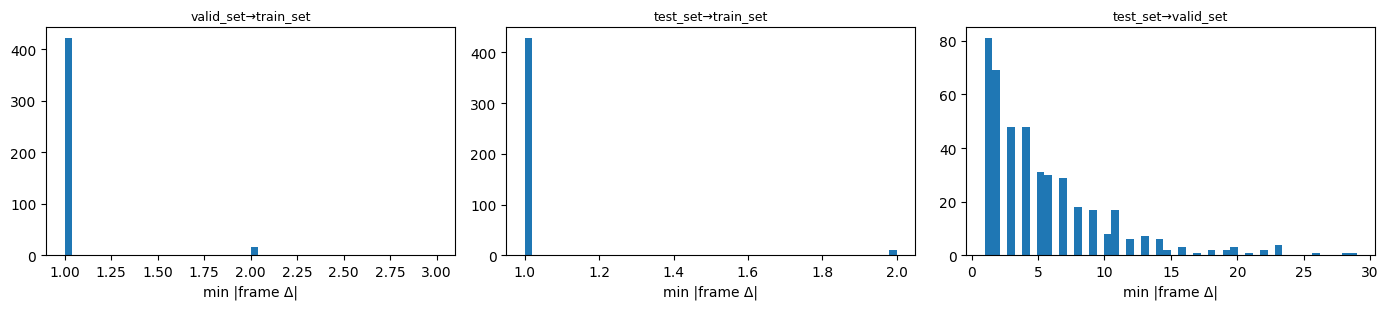

In [ ]:
pairs = [('valid_set', 'train_set'), ('test_set', 'train_set'), ('test_set', 'valid_set')]
FRAME_DIST = {}
for a, b in pairs:
    fd = frame_distance(images_df, a, b); FRAME_DIST[(a, b)] = fd
    if len(fd):
        print(f'{a} -> {b}: n={len(fd)} | <=1: {(fd.min_frame_dist <= 1).sum()} '
              f'({100 * (fd.min_frame_dist <= 1).mean():.1f}%) | <=2: {(fd.min_frame_dist <= 2).sum()} | <=5: {(fd.min_frame_dist <= 5).sum()}')
    fd.to_csv(OUT_DIR / f'A_framedist_{a}_to_{b}.csv', index=False)
fig, axes = plt.subplots(1, len(pairs), figsize=(14, 3.2))
for ax, (a, b) in zip(axes, pairs):
    fd = FRAME_DIST[(a, b)]
    if len(fd): ax.hist(fd.min_frame_dist.clip(upper=50), bins=50)
    ax.set_title(f'{a}→{b}', fontsize=9); ax.set_xlabel('min |frame Δ|')
plt.tight_layout(); plt.show()

valid_set -> train_set: near-dup(<=6): 131 (29.9%) | suspicious(<=10): 252
test_set -> train_set: near-dup(<=6): 116 (26.5%) | suspicious(<=10): 237
test_set -> valid_set: near-dup(<=6): 43 (9.8%) | suspicious(<=10): 135


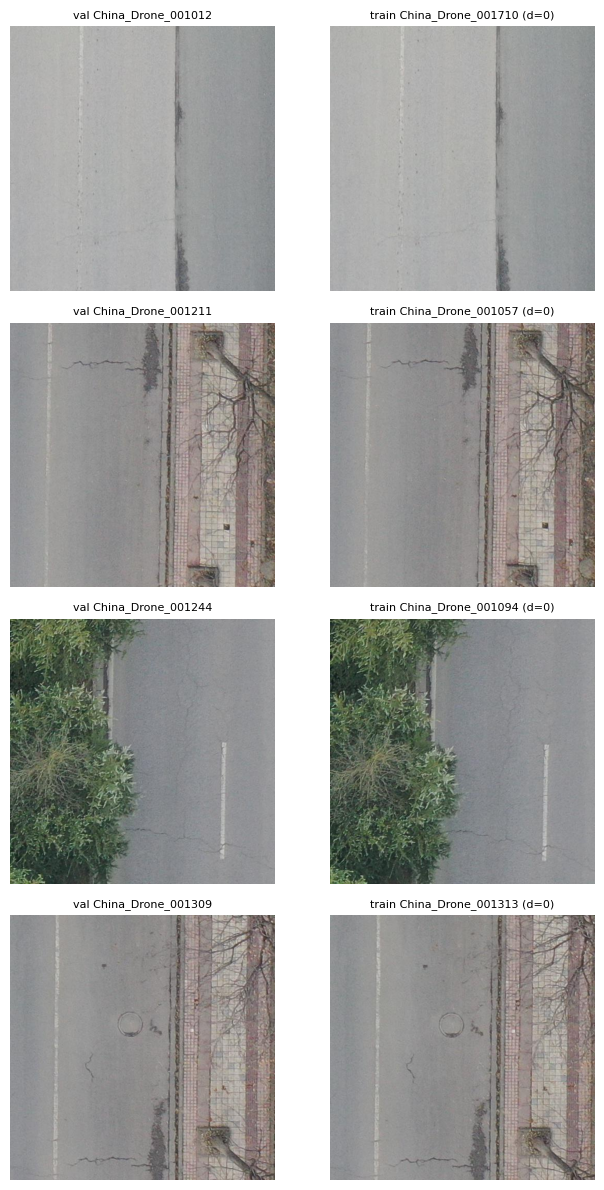

In [ ]:
HASHES = {}
for split in SPLITS:
    sub = images_df[images_df.split == split].reset_index(drop=True)
    HASHES[split] = (sub, hash_paths(sub.path.tolist()))
DUPS = {}
for a, b in pairs:
    (adf, ah), (bdf, bh) = HASHES[a], HASHES[b]
    mind, argm = hamming_cross_min(ah, bh)
    ddf = pd.DataFrame(dict(stem=adf.stem, source=adf.source, path=adf.path, min_hamming=mind,
                            match_stem=bdf.stem.values[argm], match_path=bdf.path.values[argm]))
    DUPS[(a, b)] = ddf
    print(f'{a} -> {b}: near-dup(<=6): {(ddf.min_hamming <= 6).sum()} ({100 * (ddf.min_hamming <= 6).mean():.1f}%) '
          f'| suspicious(<=10): {(ddf.min_hamming <= 10).sum()}')
    ddf[ddf.min_hamming <= 10].to_csv(OUT_DIR / f'A_neardups_{a}_to_{b}.csv', index=False)
worst = DUPS[('valid_set', 'train_set')].nsmallest(4, 'min_hamming')
if len(worst):
    fig, axes = plt.subplots(len(worst), 2, figsize=(7, 3 * len(worst))); axes = axes.reshape(-1, 2)
    for i, (_, r) in enumerate(worst.iterrows()):
        axes[i, 0].imshow(Image.open(r.path)); axes[i, 0].set_title(f'val {r.stem}', fontsize=8)
        axes[i, 1].imshow(Image.open(r.match_path)); axes[i, 1].set_title(f'train {r.match_stem} (d={r.min_hamming})', fontsize=8)
        for ax in axes[i]: ax.axis('off')
    plt.tight_layout(); plt.show()

## Part B — Stratified evaluation & error decomposition

The core "where does it fail" section: AP by aspect-ratio / size / viewpoint, bootstrap CIs, TIDE
error breakdown, confusion, matched-IoU, hardest-image gallery.

In [ ]:
def _load_cache(f):
    raw = json.loads(f.read_text())
    return {k: dict(boxes=np.array(v['boxes'], float).reshape(-1, 4),
                    conf=np.array(v['conf'], float), cls=np.array(v['cls'], int)) for k, v in raw.items()}
def _save_cache(f, preds):
    f.parent.mkdir(parents=True, exist_ok=True)
    f.write_text(json.dumps({k: dict(boxes=np.asarray(v['boxes']).tolist(), conf=np.asarray(v['conf']).tolist(),
                                     cls=np.asarray(v['cls']).tolist()) for k, v in preds.items()}))
def run_inference(model_path, image_paths, cache_file, force=False):
    if cache_file.exists() and not force:
        return _load_cache(cache_file)
    model = YOLO(str(model_path)); preds = {}
    # IMPORTANT: when given a list of paths, ultralytics relabels r.path as image0/image1/...,
    # so key by the INPUT path order (stream preserves order), not r.path.
    stems = [Path(p).stem for p in image_paths]
    for stem, r in zip(stems, model.predict(source=[str(p) for p in image_paths], imgsz=IMGSZ,
                       conf=CONF_EVAL, max_det=MAX_DET, device=device, verbose=False, stream=True, batch=8)):
        b = r.boxes
        preds[stem] = dict(boxes=b.xyxy.cpu().numpy().astype(float).reshape(-1, 4),
                           conf=b.conf.cpu().numpy().astype(float), cls=b.cls.cpu().numpy().astype(int))
    _save_cache(cache_file, preds); return preds

PRED = {}
for split in EVAL_SPLITS:
    paths = [Path(gts[split][s]['path']) for s in gts[split]]
    PRED[split] = run_inference(CKPT, paths, CACHE_DIR / f'{RUN_NAME}__{split}.json', FORCE_REINFER)
    print('inferred', split, '->', len(PRED[split]), 'images')

inferred valid_set -> 438 images
inferred test_set -> 438 images


In [ ]:
rows = []
for split in EVAL_SPLITS:
    res = evaluate(PRED[split], gts[split], classes, collect_per_image=(split == 'test_set'))
    row = dict(split=split, mAP50_95=round(res['map_pooled'], 4), mAP50=round(res['ap50_pooled'], 4),
               mAP75=round(res['ap75_pooled'], 4), macro_mAP=round(res['map_macro'], 4))
    if split == 'test_set':
        mm, lo, hi = bootstrap_map(res['per_image'], iters=BOOTSTRAP_ITERS, seed=0)
        row['boot_lo'], row['boot_hi'] = round(lo, 4), round(hi, 4)
    rows.append(row)
overall_df = pd.DataFrame(rows); print(overall_df.to_string(index=False))
overall_df.to_csv(OUT_DIR / 'B_overall.csv', index=False)
print('\nmacro_mAP should be within ~0.01 of the ultralytics test mAP50-95 in Part T.')

    split  mAP50_95  mAP50  mAP75  macro_mAP  boot_lo  boot_hi
valid_set       0.0    0.0    0.0        0.0      NaN      NaN
 test_set       0.0    0.0    0.0        0.0      0.0      0.0

macro_mAP should be within ~0.01 of the ultralytics test mAP50-95 in Part T.


   split bucket  n_gt  AP50_95  AP50  AP75  maxRecall50
test_set   AR<2   235      0.0   0.0   0.0          0.0
test_set  AR2-4   251      0.0   0.0   0.0          0.0
test_set  AR4-8   294      0.0   0.0   0.0          0.0
test_set  AR>=8   113      0.0   0.0   0.0          0.0


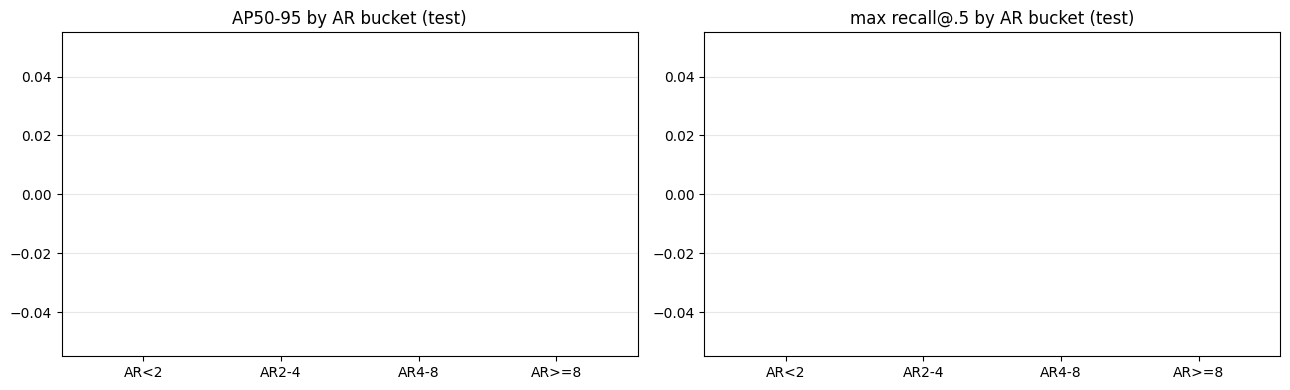

In [ ]:
def keep_ar(lab): return lambda bx: ar_bucket(box_geometry(bx)[0]) == lab
def keep_size(lab): return lambda bx: size_bucket(box_geometry(bx)[1]) == lab
ar_rows = []
for split in EVAL_SPLITS:
    for lab in AR_LABELS:
        fn = keep_ar(lab)
        res = evaluate(PRED[split], gts[split], classes, gt_keep_fn=fn, det_keep_fn=fn)
        mrec, _, ngt = recall_at(PRED[split], gts[split], classes, CONF_EVAL, 0.5, gt_keep_fn=fn)
        ar_rows.append(dict(split=split, bucket=lab, n_gt=ngt, AP50_95=round(res['map_pooled'], 4),
                            AP50=round(res['ap50_pooled'], 4), AP75=round(res['ap75_pooled'], 4),
                            maxRecall50=round(mrec, 4)))
ar_df = pd.DataFrame(ar_rows); print(ar_df[ar_df.split == 'test_set'].to_string(index=False))
ar_df.to_csv(OUT_DIR / 'B_ar_buckets.csv', index=False)
t = ar_df[ar_df.split == 'test_set'].set_index('bucket').reindex(AR_LABELS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(AR_LABELS, t.AP50_95); axes[0].set_title('AP50-95 by AR bucket (test)')
axes[1].bar(AR_LABELS, t.maxRecall50); axes[1].set_title('max recall@.5 by AR bucket (test)')
for ax in axes: ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for lab in SIZE_LABELS:
    fn = keep_size(lab)
    res = evaluate(PRED['test_set'], gts['test_set'], classes, gt_keep_fn=fn, det_keep_fn=fn)
    mrec, _, ngt = recall_at(PRED['test_set'], gts['test_set'], classes, CONF_EVAL, 0.5, gt_keep_fn=fn)
    rows.append(dict(bucket=lab, n_gt=ngt, AP50_95=round(res['map_pooled'], 4), maxRecall50=round(mrec, 4)))
print('By size bucket:'); print(pd.DataFrame(rows).to_string(index=False))
pd.DataFrame(rows).to_csv(OUT_DIR / 'B_size_buckets.csv', index=False)
thin_fn = lambda bx: box_geometry(bx)[0] >= 4.0
src_rows = []
for src in sorted(images_df.source.unique()):
    g = {k: v for k, v in gts['test_set'].items() if v.get('source') == src}
    if not g: continue
    p = {k: PRED['test_set'].get(k, dict(boxes=np.zeros((0, 4)), conf=np.zeros(0), cls=np.zeros(0, int))) for k in g}
    ra = evaluate(p, g, classes); rt = evaluate(p, g, classes, gt_keep_fn=thin_fn, det_keep_fn=thin_fn)
    src_rows.append(dict(source=src, n_img=len(g), mAP50_95=round(ra['map_pooled'], 4), thinAR4_AP=round(rt['map_pooled'], 4)))
print('\nBy source (viewpoint):'); print(pd.DataFrame(src_rows).to_string(index=False))
pd.DataFrame(src_rows).to_csv(OUT_DIR / 'B_by_source.csv', index=False)

By size bucket:
       bucket  n_gt  AP50_95  maxRecall50
   small(<32)    38      0.0          0.0
medium(32-96)   427      0.0          0.0
  large(>=96)   428      0.0          0.0

By source (viewpoint):
         source  n_img  mAP50_95  thinAR4_AP
    China_Drone    253       0.0         0.0
China_MotorBike    185       0.0         0.0


In [ ]:
tide = tide_lite(PRED['test_set'], gts['test_set'], CLASS_NAMES, conf_thr=CONF_OP)
tide.to_csv(OUT_DIR / 'B_tide_rows.csv', index=False)
print('Counts by error type (test):'); print(tide.type.value_counts().to_string())
gtb = tide[tide.type.isin(['TP', 'Miss'])]
mr = gtb.pivot_table(index='ar_bucket', columns='type', values='stem', aggfunc='count').fillna(0).reindex(AR_LABELS)
mr['miss_rate'] = (mr.get('Miss', 0) / (mr.get('Miss', 0) + mr.get('TP', 0))).round(3)
print('\nMiss rate by AR bucket:'); print(mr[['miss_rate']].to_string())
mrc = gtb.pivot_table(index='gt_cls_name', columns='type', values='stem', aggfunc='count').fillna(0)
mrc['miss_rate'] = (mrc.get('Miss', 0) / (mrc.get('Miss', 0) + mrc.get('TP', 0))).round(3)
print('\nMiss rate by class:'); print(mrc[['miss_rate']].to_string())
fps = tide[tide.type.isin(['Loc', 'Cls', 'Both', 'Dupe', 'Bkg'])]
comp = fps.type.value_counts()
if len(comp):
    comp.plot(kind='bar', figsize=(7, 3.2)); plt.title('FP composition (test)'); plt.ylabel('count')
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()

Counts by error type (test):
type
Miss    893

Miss rate by AR bucket:
type       miss_rate
ar_bucket           
AR<2             1.0
AR2-4            1.0
AR4-8            1.0
AR>=8            1.0

Miss rate by class:
type                miss_rate
gt_cls_name                  
alligator crack           1.0
longitudinal crack        1.0
pothole                   1.0
repair                    1.0
transverse crack          1.0


confusion (test):
                    longitudinal crack  transverse crack  alligator crack  pothole  repair  (missed)
longitudinal crack                   0                 0                0        0       0       437
transverse crack                     0                 0                0        0       0       241
alligator crack                      0                 0                0        0       0        87
pothole                              0                 0                0        0       0        30
repair                               0                 0                0        0       0        98
(bg FP)                              0                 0                0        0       0         0


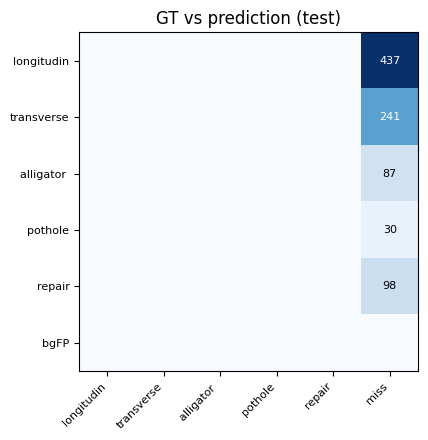

In [ ]:
cm = confusion_from_tide(tide, CLASS_NAMES)
cdf = pd.DataFrame(cm, index=CLASS_NAMES + ['(bg FP)'], columns=CLASS_NAMES + ['(missed)'])
print('confusion (test):'); print(cdf.to_string()); cdf.to_csv(OUT_DIR / 'B_confusion.csv')
fig, ax = plt.subplots(figsize=(5.5, 4.5)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(CLASS_NAMES) + 1)); ax.set_xticklabels([c[:10] for c in CLASS_NAMES] + ['miss'], rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(CLASS_NAMES) + 1)); ax.set_yticklabels([c[:10] for c in CLASS_NAMES] + ['bgFP'], fontsize=8)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='white' if cm[i, j] > cm.max() * 0.5 else 'black')
ax.set_title('GT vs prediction (test)'); plt.tight_layout(); plt.show()

Median matched IoU by AR bucket (test):
ar_bucket
AR<2    NaN
AR2-4   NaN
AR4-8   NaN
AR>=8   NaN


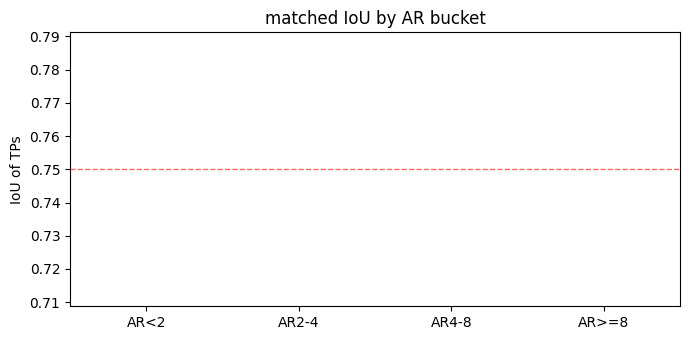

In [ ]:
tp = tide[tide.type == 'TP']
med = tp.groupby('ar_bucket').iou.median().reindex(AR_LABELS).round(3)
print('Median matched IoU by AR bucket (test):'); print(med.to_string()); med.to_csv(OUT_DIR / 'B_matched_iou.csv')
data = [tp[tp.ar_bucket == lab].iou.values for lab in AR_LABELS]
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.boxplot(data, tick_labels=AR_LABELS, showfliers=False)
ax.axhline(0.75, color='r', ls='--', lw=1, alpha=0.6); ax.set_ylabel('IoU of TPs'); ax.set_title('matched IoU by AR bucket')
plt.tight_layout(); plt.show()

saved 12 annotated images to /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_base/diagnostics/gallery


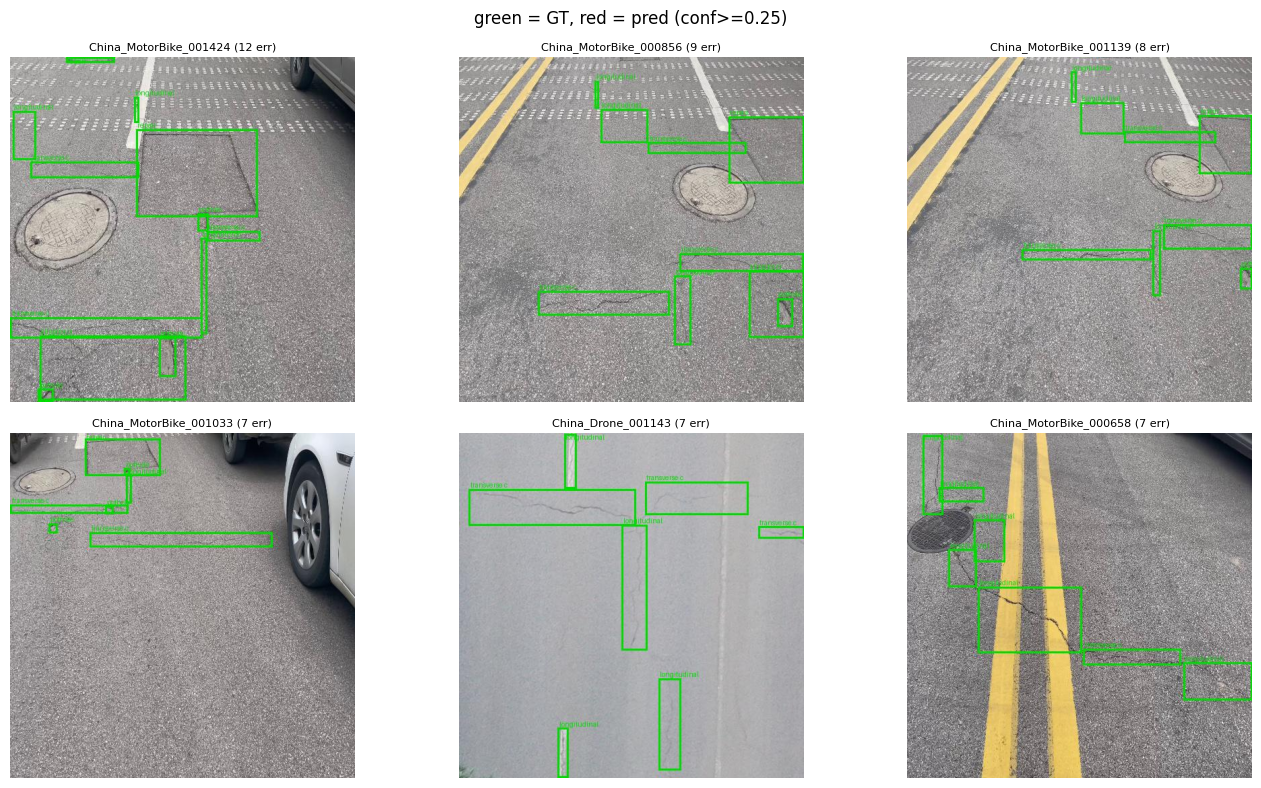

In [ ]:
errs = tide[tide.type.isin(['Miss', 'Loc', 'Cls', 'Both'])]
worst = errs.groupby('stem').size().sort_values(ascending=False).head(12)
gal = OUT_DIR / 'gallery'; gal.mkdir(parents=True, exist_ok=True)
for stem in worst.index:
    g = gts['test_set'][stem]
    p = PRED['test_set'].get(stem, dict(boxes=np.zeros((0, 4)), conf=np.zeros(0), cls=np.zeros(0, int)))
    render_errors(g['path'], g, p, CLASS_NAMES, conf_thr=CONF_OP, out_path=gal / f'{stem}.jpg')
print('saved', len(worst), 'annotated images to', gal)
show = list(worst.index[:6])
if show:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, stem in zip(axes.flat, show):
        ax.imshow(Image.open(gal / f'{stem}.jpg')); ax.set_title(f'{stem} ({worst[stem]} err)', fontsize=8); ax.axis('off')
    plt.suptitle('green = GT, red = pred (conf>=0.25)'); plt.tight_layout(); plt.show()

## Part C — Anchor coverage (geometry only)

Which GT boxes are anchor-starved per stride. Thin boxes with near-zero stride-16/32 coverage +
thin-bucket misses in Part B => the responsible component is label **assignment**.

Median in-box anchors per stride by AR bucket (train):
           anchors_s8  anchors_s16  anchors_s32  anchors_total
ar_bucket                                                     
AR<2            306.0         77.0         20.0          403.0
AR2-4           200.0         50.0         12.0          260.0
AR4-8           190.0         48.0         12.0          247.0
AR>=8           306.0         78.0         17.0          405.0

Coverage failure rates by AR bucket:
              n  pct_zero_s16  pct_zero_s32  pct_total_le4
ar_bucket                                                 
AR<2       2083         0.003         0.033          0.007
AR2-4      2023         0.004         0.041          0.002
AR4-8      2009         0.006         0.053          0.000
AR>=8       880         0.011         0.083          0.000


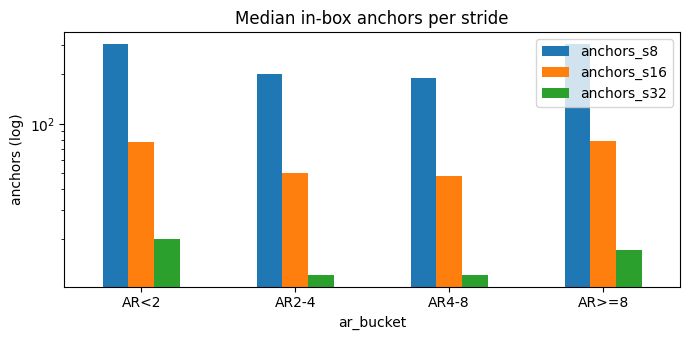

In [ ]:
anch = anchor_coverage(boxes_df[boxes_df.split == 'train_set'], imgsz=IMGSZ)
tab = anch.groupby('ar_bucket')[['anchors_s8', 'anchors_s16', 'anchors_s32', 'anchors_total']].median().reindex(AR_LABELS)
print('Median in-box anchors per stride by AR bucket (train):'); print(tab.to_string())
zero = anch.groupby('ar_bucket').agg(n=('anchors_total', 'size'),
    pct_zero_s16=('anchors_s16', lambda s: round((s == 0).mean(), 3)),
    pct_zero_s32=('anchors_s32', lambda s: round((s == 0).mean(), 3)),
    pct_total_le4=('anchors_total', lambda s: round((s <= 4).mean(), 3))).reindex(AR_LABELS)
print('\nCoverage failure rates by AR bucket:'); print(zero.to_string())
anch.to_csv(OUT_DIR / 'C_anchor_coverage.csv', index=False)
fig, ax = plt.subplots(figsize=(7, 3.5))
tab[['anchors_s8', 'anchors_s16', 'anchors_s32']].plot(kind='bar', ax=ax, logy=True)
ax.set_ylabel('anchors (log)'); ax.set_title('Median in-box anchors per stride'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## Part D — Verdict (heuristics; read with the tables above)

In [ ]:
print('=' * 78); print('VERDICT — where the base yolo26s model fails'); print('=' * 78)
leak = False
for (a, b), ddf in DUPS.items():
    if b == 'train_set':
        pct = 100 * (ddf.min_hamming <= 6).mean()
        if pct > 2: leak = True
        print(f'[A] {a}: {pct:.1f}% near-dup (dHash<=6) in train')
for (a, b), fd in FRAME_DIST.items():
    if b == 'train_set' and len(fd):
        print(f'[A] {a}: {100 * (fd.min_frame_dist <= 2).mean():.1f}% within 2 frames of train')
print('    -> ' + ('LEAKAGE material: group-aware resplit before trusting val selection.' if leak else 'no material image leakage.'))
v = overall_df[overall_df.split == 'valid_set'].mAP50_95.iloc[0]
tt = overall_df[overall_df.split == 'test_set'].mAP50_95.iloc[0]
print(f'[B] val {v:.3f} vs test {tt:.3f} (gap {v - tt:+.3f})')
s = ar_df[ar_df.split == 'test_set'].set_index('bucket')
hi = s.loc['AR>=8'] if 'AR>=8' in s.index else s.iloc[-1]
print(f"[B] AR<2 AP {s.loc['AR<2'].AP50_95:.3f} vs AR>=8 AP {hi.AP50_95:.3f} (drop {s.loc['AR<2'].AP50_95 - hi.AP50_95:+.3f}, n={int(hi.n_gt)}), AR>=8 maxRec {hi.maxRecall50:.3f}")
ngt = (tide.type.isin(['TP', 'Miss'])).sum(); miss = (tide.type == 'Miss').sum()
fp = tide[tide.type.isin(['Loc', 'Cls', 'Both', 'Dupe', 'Bkg'])].type.value_counts()
print(f'[B] miss rate {miss / max(ngt, 1):.1%} of GTs; dominant FP type: {fp.idxmax() if len(fp) else "none"}')
print('    -> Miss+thin/small => assignment (Part C/E). Loc/low-IoU => localization. Cls+D00<->D10 => orientation.')
z = zero.loc['AR>=8'] if 'AR>=8' in zero.index else None
if z is not None:
    print(f'[C] AR>=8: {z.pct_zero_s32:.0%} zero stride-32, {z.pct_total_le4:.0%} have <=4 anchors total')
    if z.pct_total_le4 > 0.2: print('    -> thin boxes anchor-starved => assignment-side fix is the lever.')
print('=' * 78)

VERDICT — where the base yolo26s model fails
[A] valid_set: 29.9% near-dup (dHash<=6) in train
[A] test_set: 26.5% near-dup (dHash<=6) in train
[A] valid_set: 99.8% within 2 frames of train
[A] test_set: 100.0% within 2 frames of train
    -> LEAKAGE material: group-aware resplit before trusting val selection.
[B] val 0.000 vs test 0.000 (gap +0.000)
[B] AR<2 AP 0.000 vs AR>=8 AP 0.000 (drop +0.000, n=113), AR>=8 maxRec 0.000
[B] miss rate 100.0% of GTs; dominant FP type: none
    -> Miss+thin/small => assignment (Part C/E). Loc/low-IoU => localization. Cls+D00<->D10 => orientation.
[C] AR>=8: 8% zero stride-32, 0% have <=4 anchors total


## Part E — Head-branch ablation (the clean, controlled component result)

Decode YOLO26's **one-to-one** (NMS-free, used at inference) vs **one-to-many** (+NMS, trained but
unused) branch from the same weights and compare per aspect-ratio bucket. Same backbone, same
features — this is the one genuinely controlled architectural comparison you can make without
forking. Large o2m-minus-o2o thin-recall gap => the NMS-free one-to-one assignment is dropping thin
cracks, which becomes your method's target. Both branches use ultralytics' own decode.

In [ ]:
# Both branches via ultralytics' OWN decode (no fragile hand-decoding):
#  - one-to-one (NMS-free): default end2end predict().
#  - one-to-many (+NMS): toggle head.end2end=False so predict() returns the dense branch, then NMS.
# Keyed by input-path order (ultralytics relabels r.path as image0/image1/...).
def _predict_to_dict(model, image_paths, use_nms, iou=NMS_IOU):
    stems = [Path(p).stem for p in image_paths]
    kw = dict(imgsz=IMGSZ, conf=CONF_EVAL, max_det=MAX_DET, device=device, verbose=False, stream=True, batch=8)
    if use_nms:
        kw['iou'] = iou
    preds = {}
    for stem, r in zip(stems, model.predict(source=[str(p) for p in image_paths], **kw)):
        b = r.boxes
        preds[stem] = dict(boxes=b.xyxy.cpu().numpy().astype(float).reshape(-1, 4),
                           conf=b.conf.cpu().numpy().astype(float), cls=b.cls.cpu().numpy().astype(int))
    return preds

def head_ablation(model_path, gt_split):
    c1, c2 = HEAD_CACHE / f'{RUN_NAME}__test__o2o.json', HEAD_CACHE / f'{RUN_NAME}__test__o2m.json'
    if c1.exists() and c2.exists() and not FORCE_REINFER:
        return _load_cache(c1), _load_cache(c2)
    paths = [gt_split[s]['path'] for s in gt_split]
    y_o2o = YOLO(str(model_path))
    if not getattr(y_o2o.model.model[-1], 'end2end', False):
        print('   head not end-to-end -> branch ablation not applicable'); return None, None
    o2o = _predict_to_dict(y_o2o, paths, use_nms=False)
    y_o2m = YOLO(str(model_path))
    try:
        y_o2m.model.model[-1].end2end = False
        y_o2m.model.end2end = False
        o2m = _predict_to_dict(y_o2m, paths, use_nms=True)
    except Exception as e:
        print('   one-to-many branch unavailable on this ultralytics version:', type(e).__name__, str(e)[:150])
        return o2o, None
    _save_cache(c1, o2o); _save_cache(c2, o2m); return o2o, o2m

HEAD_OK = False
print('== head-branch ablation (o2o = NMS-free e2e, o2m = dense branch + NMS)')
o2o, o2m = head_ablation(CKPT, gts['test_set'])
if o2o is not None and o2m is not None:
    HEAD_OK = True
    print(f'   o2o: {sum(len(v["boxes"]) for v in o2o.values())} dets | '
          f'o2m: {sum(len(v["boxes"]) for v in o2m.values())} dets across {len(o2o)} images')
else:
    print('   one branch unavailable on this version; Part-D verdict still stands.')

== head-branch ablation (o2o = NMS-free e2e, o2m = dense branch + NMS)


OutOfMemoryError: CUDA out of memory. Tried to allocate 5.35 GiB. GPU 0 has a total capacity of 14.56 GiB of which 251.81 MiB is free. Including non-PyTorch memory, this process has 14.31 GiB memory in use. Of the allocated memory 12.80 GiB is allocated by PyTorch, and 1.36 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
if HEAD_OK:
    ar8_fn = lambda bx: ar_bucket(box_geometry(bx)[0]) == 'AR>=8'
    rows = []
    for branch, P in [('o2o', o2o), ('o2m', o2m)]:
        res = evaluate(P, gts['test_set'], classes)
        row = dict(branch=branch, mAP50_95=round(res['map_pooled'], 4), mAP50=round(res['ap50_pooled'], 4),
                   mAP75=round(res['ap75_pooled'], 4))
        for lab in AR_LABELS:
            mrec, _, _ = recall_at(P, gts['test_set'], classes, CONF_EVAL, 0.5, gt_keep_fn=keep_ar(lab))
            row[f'maxRec_{lab}'] = round(mrec, 4)
        rows.append(row)
    head_df = pd.DataFrame(rows); print(head_df.to_string(index=False))
    head_df.to_csv(OUT_DIR / 'E_head_branches.csv', index=False)
    s = head_df.set_index('branch')
    print(f"\no2m+NMS - o2o(NMS-free): overall mAP {s.loc['o2m'].mAP50_95 - s.loc['o2o'].mAP50_95:+.4f} "
          f"| thin AR>=8 maxRec {s.loc['o2m']['maxRec_AR>=8'] - s.loc['o2o']['maxRec_AR>=8']:+.4f}")
    print('Positive thin-recall delta => NMS-free one-to-one assignment is the component to target.')
else:
    print('Head-branch ablation unavailable (non-e2e head or gate failed). The Part-D verdict still stands;')
    print('send me the Part-E printout and I will adapt the decoder to your ultralytics version.')

### Output → decision

Artifacts under `runs_rdd2022/yolo26s_base/diagnostics/`. The **Part-D verdict** + **Part-E head
deltas** pick your Phase-2 lever:
- big o2m−o2o thin-recall gap → **one-to-one assignment** is the lever (subclass the head; no fork).
- Loc-dominated / low matched-IoU → **localization/regression** lever (box refinement; DFL reintro = fork).
- Cls + D00↔D10 → **orientation** lever.
- flat AR buckets / big viewpoint gap → reframe toward a **viewpoint/benchmark** contribution.

Send me `B_overall.csv`, `B_ar_buckets.csv`, `E_head_branches.csv`, and the two verdict blocks.